# Counterfeit Banknote Detection

The goal of this project is to build a model that identifies counterfeit banknotes from their dimensions.

## Importing libraries

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_score
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
import joblib

## Loading and exploring the dataset

In [2]:
billets = pd.read_csv('billets.csv', sep=';')

In [3]:
billets.describe()

,diagonal,height_left,height_right,margin_low,margin_up,length
count,1500.000000,1500.000000,1500.000000,1463.000000,1500.000000,1500.00000
mean,171.958440,104.029533,103.920307,4.485967,3.151473,112.67850
std,0.305195,0.299462,0.325627,0.663813,0.231813,0.87273
min,171.040000,103.140000,102.820000,2.980000,2.270000,109.49000
25%,171.750000,103.820000,103.710000,4.015000,2.990000,112.03000
50%,171.960000,104.040000,103.920000,4.310000,3.140000,112.96000
75%,172.170000,104.230000,104.150000,4.870000,3.310000,113.34000
max,173.010000,104.880000,104.950000,6.900000,3.910000,114.44000


In [4]:
billets.head()

,is_genuine,diagonal,height_left,height_right,margin_low,margin_up,length
0,True,171.81,104.86,104.95,4.52,2.89,112.83
1,True,171.46,103.36,103.66,3.77,2.99,113.09
2,True,172.69,104.48,103.50,4.40,2.94,113.16
3,True,171.36,103.91,103.94,3.62,3.01,113.51
4,True,171.73,104.28,103.46,4.04,3.48,112.54


In [5]:
billets.isna().sum()

is_genuine       0
diagonal         0
height_left      0
height_right     0
margin_low      37
margin_up        0
length           0
dtype: int64

There are 37 missing values for margin_low.

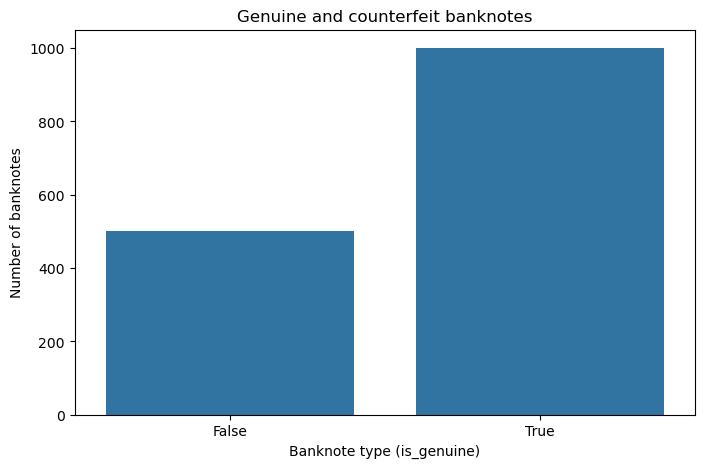

In [6]:
# histogram of the target variable
plt.figure(figsize=(8, 5))
sns.countplot(x='is_genuine', data=billets)
plt.title('Genuine and counterfeit banknotes')
plt.xlabel('Banknote type (is_genuine)')
plt.ylabel('Number of banknotes')
plt.show()

The dataset is not imbalanced.

## Imputing missing values with a regression

In [7]:
df_num = billets.select_dtypes(include=[np.number])
target = "margin_low"  

df_train = df_num[df_num[target].notna()]
df_pred  = df_num[df_num[target].isna()]

X_train = df_train.drop(columns=target)
y_train = df_train[target]

X_pred = df_pred.drop(columns=target)

lr = LinearRegression()
lr.fit(X_train, y_train)

billets.loc[billets[target].isna(), target] = lr.predict(X_pred)

In [8]:
billets.isna().sum()

is_genuine      0
diagonal        0
height_left     0
height_right    0
margin_low      0
margin_up       0
length          0
dtype: int64

The missing values have been imputed.

## Building the counterfeit detection model

We will build 3 algorithms, compare their performance and keep the best one.

### SVM

In [9]:
X = billets.drop(columns="is_genuine")
y = billets["is_genuine"]

pipe_svm = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel="linear", probability=True, random_state=42))
])

cv = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1"
}

cv_results = cross_validate(
    pipe_svm,
    X,
    y,
    cv=cv,
    scoring=scoring,
    return_train_score=False
)

for metric in cv_results:
    if "test" in metric:
        scores = cv_results[metric]
        print(f"{metric} : {scores.mean():.3f} ± {scores.std():.3f}")

test_accuracy : 0.991 ± 0.007
test_precision : 0.990 ± 0.010
test_recall : 0.997 ± 0.005
test_f1 : 0.994 ± 0.005


### Random forest

In [10]:
rf = RandomForestClassifier(
    n_estimators=300,
    random_state=42
)

cv_10 = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)

cv_rf = cross_validate(
    rf,
    X,
    y,
    cv=cv_10,
    scoring=scoring,
    return_train_score=False
)

for metric in cv_rf:
    if "test" in metric:
        scores = cv_rf[metric]
        print(f"{metric} : {scores.mean():.3f} ± {scores.std():.3f}")

test_accuracy : 0.991 ± 0.009
test_precision : 0.990 ± 0.010
test_recall : 0.996 ± 0.007
test_f1 : 0.993 ± 0.007


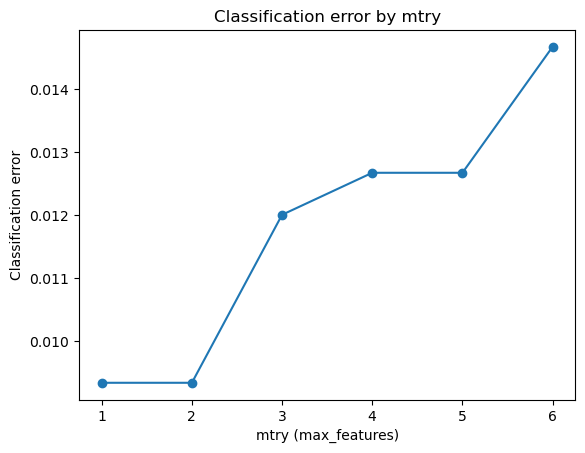

In [11]:
# Split X / y
X = billets.drop(columns="is_genuine")
y = billets["is_genuine"]

# Number of features
n_features = X.shape[1]

# mtry values tested
mtry_values = range(1, n_features + 1)
errors = []

# 10-fold cross-validation
cv_10 = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)

# Loop over mtry
for mtry in mtry_values:
    rf = RandomForestClassifier(
        n_estimators=300,
        max_features=mtry,
        random_state=42
    )

    scores = cross_val_score(
        rf,
        X,
        y,
        cv=cv_10,
        scoring="accuracy"
    )

    errors.append(1 - scores.mean())

# Plot
plt.figure()
plt.plot(mtry_values, errors, marker='o')
plt.xlabel("mtry (max_features)")
plt.ylabel("Classification error")
plt.title("Classification error by mtry")
plt.show()


The error is lowest with 2 features, so we re-run the forest with this parameter.

In [12]:
rf = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    max_features=2
)

cv_10 = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)

cv_rf = cross_validate(
    rf,
    X,
    y,
    cv=cv_10,
    scoring=scoring,
    return_train_score=False
)

for metric in cv_rf:
    if "test" in metric:
        scores = cv_rf[metric]
        print(f"{metric} : {scores.mean():.3f} ± {scores.std():.3f}")

test_accuracy : 0.991 ± 0.009
test_precision : 0.990 ± 0.010
test_recall : 0.996 ± 0.007
test_f1 : 0.993 ± 0.007


### Gradient boosting

In [13]:
gb = GradientBoostingClassifier(
    n_estimators=200,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

cv_10 = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1"
}

cv_gb = cross_validate(
    gb,
    X,
    y,
    cv=cv_10,
    scoring=scoring,
    return_train_score=False
)

for metric in cv_gb:
    if "test" in metric:
        scores = cv_gb[metric]
        print(f"{metric} : {scores.mean():.3f} ± {scores.std():.3f}")

test_accuracy : 0.989 ± 0.011
test_precision : 0.990 ± 0.009
test_recall : 0.994 ± 0.009
test_f1 : 0.992 ± 0.008


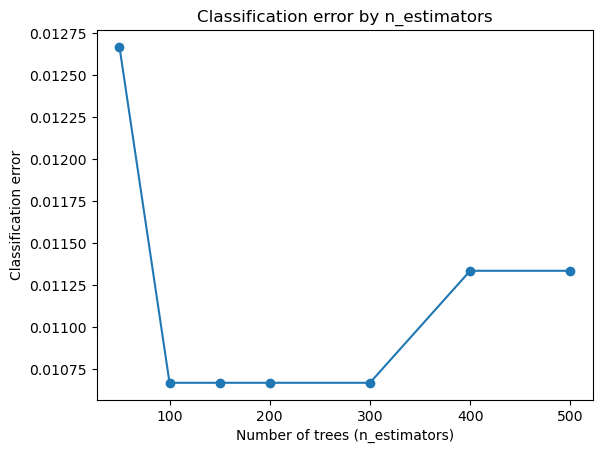

In [14]:
# Values tested
n_estimators_values = [50, 100, 150, 200, 300, 400, 500]
errors = []

cv_10 = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)

for n in n_estimators_values:
    gb = GradientBoostingClassifier(
        n_estimators=n,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    )

    scores = cross_val_score(
        gb,
        X,
        y,
        cv=cv_10,
        scoring="accuracy"
    )

    errors.append(1 - scores.mean())

# Plot
plt.figure()
plt.plot(n_estimators_values, errors, marker='o')
plt.xlabel("Number of trees (n_estimators)")
plt.ylabel("Classification error")
plt.title("Classification error by n_estimators")
plt.show()


The choice of 200 trees was consistent.

## Choosing the method

| Model               | Accuracy (± std) | Precision (± std) | Recall (± std) | F1-score (± std) |
|---------------------|------------------|-------------------|----------------|------------------|
| SVM                 | 0.991 ± 0.007    | 0.990 ± 0.010     | 0.997 ± 0.005  | 0.994 ± 0.005    |
| Random Forest       | 0.991 ± 0.009    | 0.990 ± 0.010     | 0.996 ± 0.007  | 0.993 ± 0.007    |
| Gradient Boosting   | 0.989 ± 0.011    | 0.990 ± 0.009     | 0.994 ± 0.009  | 0.992 ± 0.008    |


All three models show high and stable performance.  
The SVM achieves the best overall results, especially for F1-score and recall, indicating an excellent ability to generalise.  
The random forest offers comparable performance, while gradient boosting is slightly behind but still performs very well.


## What the SVM's performance metrics mean in practice

The performance metrics show concretely how the model behaves.

#### Accuracy
Accuracy is the overall proportion of banknotes classified correctly.

**Concrete example:**
If the model is tested on 1,000 banknotes and accuracy is 0.991, about **991 banknotes are classified correctly** and **9 are misclassified**, across both classes.

This metric gives an overall view of performance, but on its own it does not show what type of errors are made.

---

#### Precision
Precision measures how reliable the model's positive predictions are.

**Concrete example:**
If the model predicts that a banknote is genuine 100 times and precision is 0.99, then **99 of these banknotes are actually genuine** and **1 is in fact counterfeit**.

High precision matters when we want to **avoid accepting counterfeit banknotes**.

---

#### Recall
Recall measures the model's ability to detect all genuine banknotes.

**Concrete example:**
If 1,000 banknotes are actually genuine and recall is 0.997, the model **correctly identifies 997 genuine banknotes** but **misses 3**, which are wrongly classified as counterfeit.

High recall is crucial when we want to **minimise the number of genuine banknotes wrongly rejected**.

---

#### F1-score
The F1-score combines precision and recall into a single measure.

**Concrete example:**
An F1-score of 0.994 shows that the model has an **excellent balance** between:
- the reliability of its predictions (precision),
- its ability to correctly detect genuine banknotes (recall).

---

#### Standard deviation (±)
The standard deviation shows how stable the model's performance is across cross-validation folds.

**Concrete example:**
An F1-score of 0.994 ± 0.005 means that, depending on the subset of data used for training and testing, the F1-score varies very little (between about 0.989 and 0.999).

A low standard deviation shows that the model is **robust** and **generalises well**, regardless of how the dataset is split.


## Saving the SVM

In [15]:
pipe_svm.fit(X, y)

joblib.dump(pipe_svm, "svm_billets_model.pkl")

['svm_billets_model.pkl']